# **Infer `Nucleus`**

***Prior to this notebook, you should have already run through [1.0_image_setup](1.0_image_setup.ipynb).***


In notebooks 1.1 through 1.8, we will go over the implementation of `infer-subc` in the Napari plugin called  `organelle-segmenter-plugin`. The steps outlined in each notebook correlate to the workflow steps from the plugin. Here, you will gain knowledge of what `infer-subc` functions are involved in each of those steps.

The segmentation workflows are completely independent of each other and can be run in any order. The current notebook segments the `cell mask` and `nucleus` based on a multichannel input image. See below for more details on the input image type required. Consider the other versions of notebooks 1.1 outlined below as well.

# <MARK> **NEED TO UPDATE THE INFORMATION HERE ONCE THE NEW WORKFLOW HAS BEEN FINALIZED**

## **Segment nuclei from inverse of cytoplasm**
<ins>Goals:</ins> Create a nuclei segmentation pipeline for images that do not contain a nuclei label; this would specificially be in advance of something like CellPose where a nuclei label (or a segmented nuclei) would be necessary.

Current thought process:
1. Utilize the same pipeline as is in 1.1a up until the cell mask if created
2. Add a further refinement step to remove any identified objects that touch the edge of the image (nuclei will always be in the middle)


--------------


---------------------
## **IMPORTS AND LOAD IMAGE**
Details about the functions included in this subsection are outlined in the [`1.0_image_setup`](1.0_image_setup.ipynb) notebook. Please visit that notebook first if you are confused about any of the code included here.

#### &#x1F3C3; **Run code; no user input required**

In [1]:
from pathlib import Path
import os
import seaborn as sns

import numpy as np
import pandas as pd
import napari
from napari.utils.notebook_display import nbscreenshot

from skimage.morphology import binary_dilation, binary_erosion
from skimage.segmentation import clear_border
import numpy as np

from infer_subc.core.file_io import (read_czi_image, 
                                     export_inferred_organelle,
                                     list_image_files,
                                     sample_input)
from infer_subc.core.img import *
from infer_subc.organelles import non_linear_cellmask_transform

%load_ext autoreload
%autoreload 2

#### &#x1F6D1; &#x270D; **User Input Required:**

Please specify the following information about your data: `sample_data_type`, `data_root_path`, `in_data_path`, `im_type`, and `out_data_path`.

In [2]:
### USER INPUT REQUIRED ###
sample_data_type = None


# Edit locations indicated by "USER SPECIFIED".
data_root_path = Path(r"J:\Cohen Lab\Maria Clara\2_Lab data\1_Multispectral data\2026\iAstrocytes Differentiation") # r"J:\Cohen Lab\Kajal\For Shannon\iAstroD28")

in_data_path = data_root_path / "iAstrocytes amyloid d34 - Deconvolved/tiff" # "Deconvolution"

im_type = ".tiff"

out_data_path = data_root_path / "20261006_SR_test-seg"

#### &#x1F3C3; **Run code; no user input required**

In [3]:
# If sample_data_type is set to "neuron_1", "astrocyte", "neuron_2" or "iPSC" then the sample data is used and the directories are set
if sample_data_type != None:
    data_root_path, im_type, in_data_path, out_data_path = sample_input(sample_data_type)

# Create the output directory to save the segmentation outputs in.
if not Path.exists(out_data_path):
    Path.mkdir(out_data_path)
    print(f"making {out_data_path}")

# Create a list of the file paths for each image in the input folder. Select test image path.
img_file_list = list_image_files(in_data_path,im_type)
pd.set_option('display.max_colwidth', None)
pd.DataFrame({"Image Name":img_file_list})

,Image Name
0,J:\Cohen Lab\Maria Clara\2_Lab data\1_Multispectral data\2026\iAstrocytes Differentiation\iAstrocytes amyloid d34 - Deconvolved\tiff\04162026_ZS_iAtro_day34_SOX9NFIA1_BR03-ab1-42_N01_Unmixing_cmle.ome.tiff
1,J:\Cohen Lab\Maria Clara\2_Lab data\1_Multispectral data\2026\iAstrocytes Differentiation\iAstrocytes amyloid d34 - Deconvolved\tiff\04162026_ZS_iAtro_day34_SOX9NFIA1_BR03-ab1-42_N02_Unmixing_cmle.ome.tiff
2,J:\Cohen Lab\Maria Clara\2_Lab data\1_Multispectral data\2026\iAstrocytes Differentiation\iAstrocytes amyloid d34 - Deconvolved\tiff\04162026_ZS_iAtro_day34_SOX9NFIA1_BR03-ab1-42_N03_Unmixing_cmle.ome.tiff
3,J:\Cohen Lab\Maria Clara\2_Lab data\1_Multispectral data\2026\iAstrocytes Differentiation\iAstrocytes amyloid d34 - Deconvolved\tiff\04162026_ZS_iAtro_day34_SOX9NFIA1_BR03-ab1-42_N06_Unmixing_cmle.ome.tiff
4,J:\Cohen Lab\Maria Clara\2_Lab data\1_Multispectral data\2026\iAstrocytes Differentiation\iAstrocytes amyloid d34 - Deconvolved\tiff\04162026_ZS_iAtro_day34_SOX9NFIA1_BR03-ab1-42_N07_Unmixing_cmle.ome.tiff
...,...
69,J:\Cohen Lab\Maria Clara\2_Lab data\1_Multispectral data\2026\iAstrocytes Differentiation\iAstrocytes amyloid d34 - Deconvolved\tiff\04222026_ZS_iAtro_day34_SOX9NFIA1_BR05_N09_Unmixing_cmle.ome.tiff
70,J:\Cohen Lab\Maria Clara\2_Lab data\1_Multispectral data\2026\iAstrocytes Differentiation\iAstrocytes amyloid d34 - Deconvolved\tiff\04222026_ZS_iAtro_day34_SOX9NFIA1_BR05_N11_Unmixing_cmle.ome.tiff
71,J:\Cohen Lab\Maria Clara\2_Lab data\1_Multispectral data\2026\iAstrocytes Differentiation\iAstrocytes amyloid d34 - Deconvolved\tiff\04222026_ZS_iAtro_day34_SOX9NFIA1_BR05_N12_Unmixing_cmle.ome.tiff
72,J:\Cohen Lab\Maria Clara\2_Lab data\1_Multispectral data\2026\iAstrocytes Differentiation\iAstrocytes amyloid d34 - Deconvolved\tiff\04222026_ZS_iAtro_day34_SOX9NFIA1_BR05_N14_Unmixing_cmle.ome.tiff


#### &#x1F6D1; &#x270D; **User Input Required:**

Use the list above to specify which image you wish to analyze based on its index: `test_img_n`

In [4]:
#### USER INPUT REQUIRED ###
test_img_n = 0

#### &#x1F3C3; **Run code; no user input required**

Metadata information
File path: J:\Cohen Lab\Maria Clara\2_Lab data\1_Multispectral data\2026\iAstrocytes Differentiation\iAstrocytes amyloid d34 - Deconvolved\tiff\04162026_ZS_iAtro_day34_SOX9NFIA1_BR03-ab1-42_N01_Unmixing_cmle.ome.tiff
Channel 0 name: 04162026_ZS_iAtro_day34_SOX9NFIA1_BR03-ab1-42_N01_Unmixing_cmle.ome :: Channel 0
Channel 1 name: 04162026_ZS_iAtro_day34_SOX9NFIA1_BR03-ab1-42_N01_Unmixing_cmle.ome :: Channel 1
Channel 2 name: 04162026_ZS_iAtro_day34_SOX9NFIA1_BR03-ab1-42_N01_Unmixing_cmle.ome :: Channel 2
Channel 3 name: 04162026_ZS_iAtro_day34_SOX9NFIA1_BR03-ab1-42_N01_Unmixing_cmle.ome :: Channel 3
Channel 4 name: 04162026_ZS_iAtro_day34_SOX9NFIA1_BR03-ab1-42_N01_Unmixing_cmle.ome :: Channel 4
Channel 5 name: 04162026_ZS_iAtro_day34_SOX9NFIA1_BR03-ab1-42_N01_Unmixing_cmle.ome :: Channel 5
Channel 6 name: 04162026_ZS_iAtro_day34_SOX9NFIA1_BR03-ab1-42_N01_Unmixing_cmle.ome :: Channel 6
Channel 7 name: 04162026_ZS_iAtro_day34_SOX9NFIA1_BR03-ab1-42_N01_Unmixing_cmle.ome

07-Oct-26 13:12:46 - vispy    - WARNING  - QWindowsWindow::setGeometry: Unable to set geometry 1086x661+2322-1106 (frame: 1102x700+2314-1137) on QWidgetWindow/"_QtMainWindowClassWindow" on "\\.\DISPLAY2". Resulting geometry: 867x527+2321-1113 (frame: 883x566+2313-1144) margins: 8, 31, 8, 8 minimum size: 385x506 MINMAXINFO maxSize=0,0 maxpos=0,0 mintrack=401,545 maxtrack=0,0)



Proceed to Napari window to view your selected image.


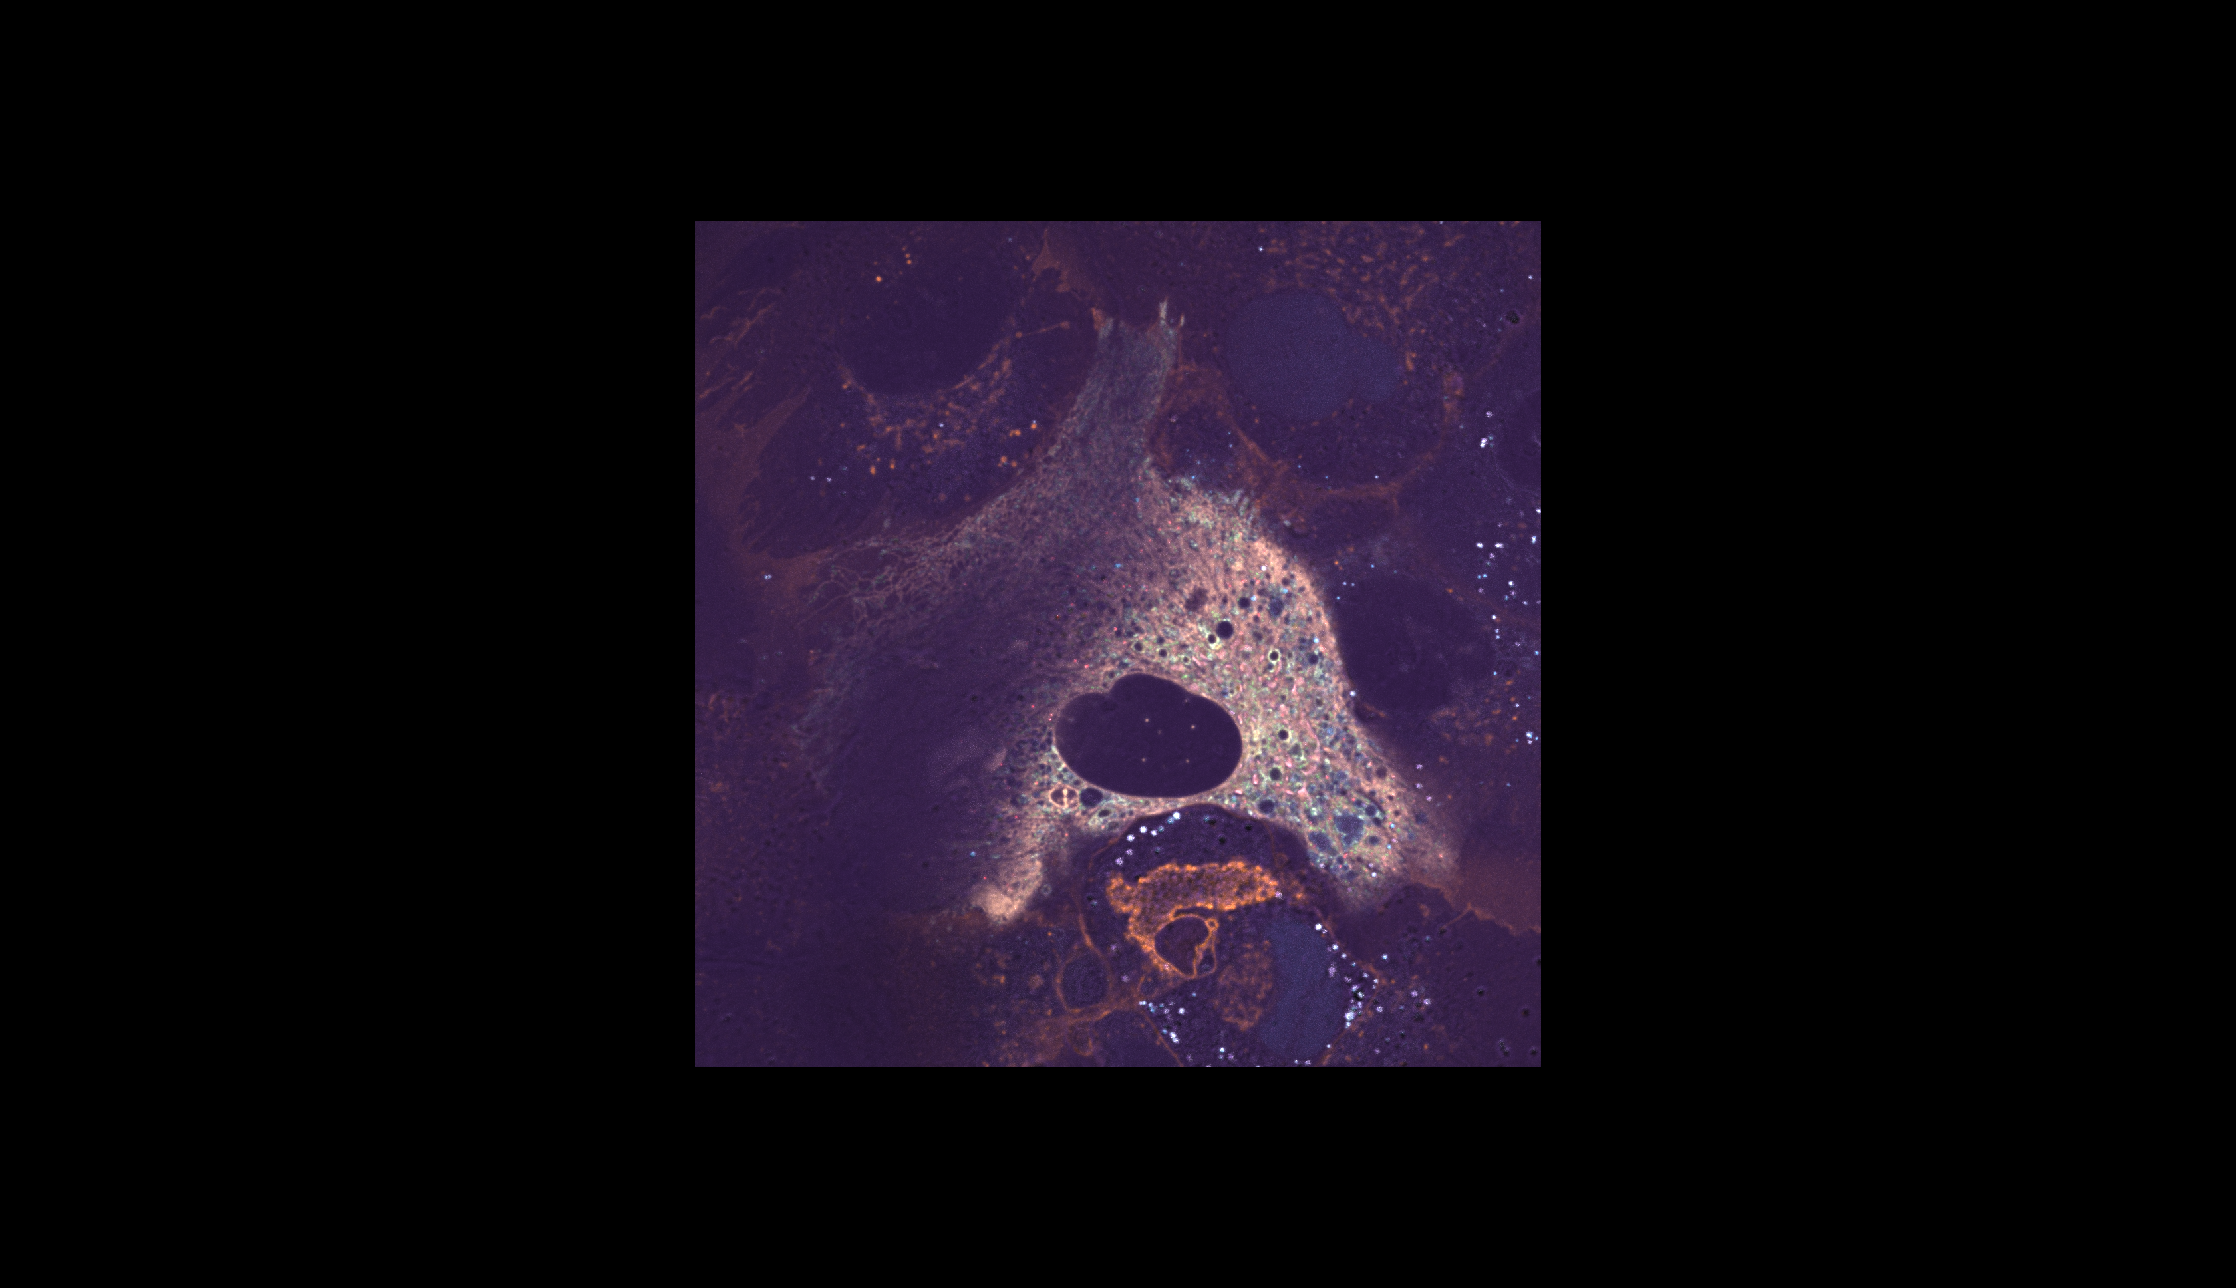

In [13]:
# Read in the image and metadata as an ndarray and dictionary from the test image selected above. 
test_img_name = img_file_list[test_img_n]
img_data,meta_dict = read_czi_image(test_img_name)

# Define some of the metadata features and print them.
channel_names = meta_dict['name']
meta = meta_dict['metadata']['aicsimage']
scale = meta_dict['scale']
channel_axis = meta_dict['channel_axis']
file_path = meta_dict['file_name']

print("Metadata information")
print(f"File path: {file_path}")
for i in list(range(len(channel_names))):
    print(f"Channel {i} name: {channel_names[i]}")
print(f"Scale (ZYX): {scale}")
print(f"Channel axis: {channel_axis}")

# open viewer and add images
viewer = napari.Viewer()
color_map = sns.color_palette("Paired").as_hex()
viewer.layers.clear()
for i in list(range(len(channel_names))):
    viewer.add_image(img_data[i],
                     scale=scale,
                     name=f"Channel {i}",
                     blending="additive",
                     colormap=color_map[i])
viewer.grid.enabled = False
viewer.reset_view()
print("\nProceed to Napari window to view your selected image.")

# screenshot viewer
nbscreenshot(viewer, canvas_only = True)

-----

## **EXTRACTION**

### **`STEP 1` - Create composite image of the CYTOPLASM**

&#x1F453; **FYI:** This code block creates a composite image of the cytoplasmic organelle/structure channels with the goal of creating an intensity image that has a lot of signal in the cytoplasm of the cell, but NOT the nucleus. 

Below, the intensity of each channel is combined with specified weights. If a weight of 0 is specified, that channel will be excluded.

#### &#x1F6D1; &#x270D; **User Input Required:**

Please specify the following values:
- `w0`: the weight of channel 0 (the first channel); a value of 0 will exclude this channel from the compostite; large values will cause this channel to be more prominent in the final composite image
- `w1`: the weight of channel 1
- `w2`: the weight of channel 2
- `w3`: the weight of channel 3
- `w4`: the weight of channel 4
- `w5`: the weight of channel 5
- `w6`: the weight of channel 6
- `w7`: the weight of channel 7
- `w8`: the weight of channel 8
- `w9`: the weight of channel 9
- `rescale`: "True" rescales the image so that the pixel/voxel with the highest intensity is set to 1 and the one with the lowest intensity is set to 0; "False" leaves the combined intensity values as is after the composite is made

In [ ]:
# #### USER INPUT REQUIRED ### KK
# w0 = 0
# w1 = 8
# w2 = 5
# w3 = 1
# w4 = 20
# w5 = 0
# w6 = 0
# w7 = 0
# w8 = 0
# w9 = 0
# cyto_rescale = True

#### USER INPUT REQUIRED ### MCZ
w0 = 2
w1 = 2
w2 = 2
w3 = 2
w4 = 2
w5 = 2
w6 = 5
w7 = 5
w8 = 0
w9 = 0
cyto_rescale = True

#### &#x1F3C3; **Run code; no user input required**

&#x1F453; **FYI:** This code block creates the composite and optionally rescales the image based on the settings above. The image is then added to Napari as a new layer for visual comparison to the input image. 

Use the Napari viewer to iteratively adjust the weights selected above.

In [ ]:
# make aggregate and optionally rescale
struct_img_raw = make_aggregate(img_data,
                                weight_ch0= w0,
                                weight_ch1= w1,
                                weight_ch2= w2,
                                weight_ch3= w3,
                                weight_ch4= w4,
                                weight_ch5= w5,
                                weight_ch6= w6,
                                weight_ch7= w7,
                                weight_ch8= w8,
                                weight_ch9= w9,
                                rescale = cyto_rescale)

# adding image to Napari as a new layer
viewer.grid.enabled = False
viewer.reset_view()
viewer.add_image(struct_img_raw, scale=scale, name="1-Cyto: Create composite")

-----
## **PRE-PROCESSING**

### **`STEP 2` - Rescale and smooth image**

&#x1F453; **FYI:** This code block rescales the composite image so that the pixel/voxel with the highest intensity is set to 1 and the one with the lowest intensity is set to 0. This process helps to normalize the intensity range for each image included in the dataset. The image is then *optionally* smoothed using a Gaussian and/or median filter; smoothing occurs prior to rescaling if it is used. 

#### &#x1F6D1; &#x270D; **User Input Required:**

Please specify the amount of filter to use for each method. Higher values indicate more smoothing:
- `med_filter_size`: the size of the median filter to apply; if 0 is used, no filter will be applied
- `gaussian_smoothing_sigma`: the sigma to apply in the Gaussian filtering step; if 0 is used, no filter will be applied

In [ ]:
# #### USER INPUT REQUIRED ### KK
# cyto_med_filter_size = 3
# cyto_gaussian_smoothing_sigma = 3

#### USER INPUT REQUIRED ### MCZ
cyto_med_filter_size = 3
cyto_gaussian_smoothing_sigma = 3

#### &#x1F3C3; **Run code; no user input required**

&#x1F453; **FYI:** This code block rescales the image and applies the specified median and Gaussian filters. The image is then added to Napari as a new layer for visual comparison to the input image. 

Use the Napari viewer to iteratively adjust the smoothing settings selected above.

In [ ]:
# rescaling and smoothing input image
structure_img_smooth = scale_and_smooth(struct_img_raw,
                                        median_size = cyto_med_filter_size, 
                                        gauss_sigma = cyto_gaussian_smoothing_sigma)


# adding image to Napari as a new layer
viewer.add_image(structure_img_smooth, scale=scale, name="2-Cyto: Rescale and Smooth")

### **`STEP 3` - Log transform + Scharr edge detection**

#### &#x1F3C3; **Run code; no user input required**

&#x1F453; **FYI:** This code block applies a log transform and the [Scharr](https://scikit-image.org/docs/stable/api/skimage.filters.html#skimage.filters.scharr) edge detection filter ahead of the segmentation step that occures next. The edge detection filter helps to define the transitions between areas of high and low signal, hopefully helping the segmentation process.

Use the Napari viewer to iteratively adjust the filter settings as needed.

*Hint: it may be helpful to readjust the composite and smoothing settings to improve the outcome of this step.*

In [ ]:
# log scale the image, apply the scharr edge detection filter to logged image, add the two images together
composite_cytomask = non_linear_cellmask_transform(structure_img_smooth)

# adding image to Napari as a new layer
viewer.add_image(composite_cytomask, scale=scale, name="3-Cyto: Log Scharr edge detectiong")

-----
## **CORE-PROCESSING**

### **`STEP 4` - Global + local thresholding (AICSSeg – MO) of the CYTOPLASM**

&#x1F453; **FYI:** This code block creates a semantic segmentation of the cytoplasmic area without filling the nucleus. It is okay to over segment the extracellular space.

`Semantic segmentation` is the process of deciding whether a pixel/voxel should be included in an object (labeled with a value of 1) or should be considered as part of the background (labeled with a value of 0). A semantic segmentation does not discern individual objects from one another.

The masked_object_filter utilizes the 'MO' filter from the [`aics-segmentation`](https://github.com/AllenCell/aics-segmentation) package. AICS documentation states: "The algorithm is a hybrid thresholding method combining two levels of thresholds. The steps are: [1] a global threshold is calculated, [2] extract each individual connected componet after applying the global threshold, [3] remove small objects, [4] within each remaining object, a local Otsu threshold is calculated and applied with an optional local threshold adjustment ratio (to make the segmentation more and less conservative). An extra check can be used in step [4], which requires the local Otsu threshold larger than 1/3 of global Otsu threhsold and otherwise this connected component is discarded."

#### &#x1F6D1; &#x270D; **User Input Required:**

Please specify the following values:
- `thresh_method`: the global thresholding method; options include 'tri'/'triangle, 'med'/'median' or 'ave'/'ave_tri_med'. Triangle implements the [skimage.filters.threshold_triangle](https://scikit-image.org/docs/stable/api/skimage.filters.html#skimage.filters.threshold_triangle) method, median utilizes the 50th percentile of the intensities, and ave uses the average of the two methods to calculate the lower bound of the global threshold.
- `cell_wise_min_area`: the minimum expected size of your object; smaller objects will be removed prior to local thresholding
- `thresh_adj`: adjustment to make to the local threshold; larger values make the segmentation more stringent (less area included)

In [ ]:
# #### USER INPUT REQUIRED ### KK
# cyto_thresh_method = 'med'
# cyto_cutoff_size =  50
# cyto_thresh_adj = 0.3

#### USER INPUT REQUIRED ### MCZ
cyto_thresh_method = 'med'
cyto_cutoff_size =  50
cyto_thresh_adj = 0.8

#### &#x1F3C3; **Run code; no user input required**

&#x1F453; **FYI:** This code block executes the MO filter using the settings above.

Use the Napari viewer to iteratively adjust the filter settings as needed.

In [ ]:
# threshold the composite image after log/edge detection using the MO filter function from aicssegmentation - this applies a global threshold, then a local threshold to produce a semantic segmentation
bw = masked_object_thresh(composite_cytomask, 
                          global_method=cyto_thresh_method, 
                          cutoff_size=cyto_cutoff_size, 
                          local_adjust=cyto_thresh_adj)

# adding image to Napari as a new layer
viewer.add_image(bw, scale=scale, name="4-Cyto: MO filter", opacity=0.3, colormap="cyan", blending='additive')

-----
## **POST-PROCESSING**

### **`STEP 5` - Remove small holes and objects in the cytoplasm mask**

&#x1F453; **FYI:** This code block cleans up the semantic segmentation of the cytoplasm by filling small holes and/or removing small objects that can be considered errors in the initial segmentation. The goal here is to maintain the nuclei hole in the segmentation mask while removing and other small holes or extraneous objects that are not part of the main cell. It is still okay for areas outside of the cell to be segmented, but they shouldn't contain any/many holes or extra small disconnected parts.

#### &#x1F6D1; &#x270D; **User Input Required:**

Please specify the following values:
- `hole_min_width`: the width of the smallest hole to be filled
- `hole_max_width`: the width of the largest hole to be filled
- `small_object_width`: the width of the largest object to be removed; any object smaller than this size will be removed
- `fill_filter_method`: "3D" processes the image taking into account segmentation values in three dimensions (XYZ); "slice-by-slice" processes each Z-slice in the image separately, not considering the segmentation results in higher or lower Z planes.

In [ ]:
# #### USER INPUT REQUIRED ### KK
# cyto_hole_min_width = 0
# cyto_hole_max_width = 20

# cyto_small_object_width = 50

# cyto_fill_filter_method = "slice_by_slice"

#### USER INPUT REQUIRED ### MCZ
cyto_hole_min_width = 0
cyto_hole_max_width = 20

cyto_small_object_width = 50

cyto_fill_filter_method = "3D"

#### &#x1F3C3; **Run code; no user input required**

&#x1F453; **FYI:** This code block fills small holes and removes small objects using the settings above.

Use the Napari viewer to iteratively adjust the filter settings as needed. 

In [ ]:
# fill small holes and remove small objects
cleaned_img2 = fill_and_filter_linear_size(bw, 
                                           hole_min=cyto_hole_min_width, 
                                           hole_max=cyto_hole_max_width, 
                                           min_size=cyto_small_object_width,
                                           method=cyto_fill_filter_method)

# force all sections of the cytoplasm to be labeled as 1 even if they are separated
cytoplasm_mask = label_bool_as_uint16(cleaned_img2)

# adding image to Napari as a new layer
viewer.add_image(cytoplasm_mask, scale=scale, name="5-Cyto: Fill holes and remove small objects", colormap="magenta")

-----
## **POST-POST-PROCESSING**

### **`STEP 6` - Close nuclei hole in cytoplasm**

&#x1F453; **FYI:** This code block dilates the cytoplasm mask to close any gaps in the cytoplasm mask, fills the nucleus hole in the cytoplasm mask to generate the cell mask, and erodes the mask back to its original size to maintain a more accurate nuclei volume.

#### &#x1F6D1; &#x270D; **User Input Required:**

Please specify the following values:
- `hole_min_width`: the width of the smallest hole to be filled
- `hole_max_width`: the width of the largest hole to be filled
- `fill_filter_method`: "3D" processes the image taking into account segmentation values in three dimensions (XYZ); "slice-by-slice" processes each Z-slice in the image separately, not considering the segmentation results in higher or lower Z planes.

*Note: the fill_and_filter_linear_size function is utilized here, but only the hole feature is initiated.*

In [ ]:
# #### USER INPUT REQUIRED ### KK
# nuc_hole_min_width = 50
# nuc_hole_max_width = 200
# nuc_fill_filter_method = "3D"

#### USER INPUT REQUIRED ### MCZ
nuc_hole_min_width = 50
nuc_hole_max_width = 200
nuc_fill_filter_method = "3D"

#### &#x1F3C3; **Run code; no user input required**

&#x1F453; **FYI:** This code block fills the nucleus hole using the settings above.

Use the Napari viewer to iteratively adjust the filter settings as needed. 

In [ ]:
# dilate mask area
cytoplasm_dilated = binary_dilation(cytoplasm_mask)

# fill the hole of the nucleus
cytoplasm_filled = fill_and_filter_linear_size(cytoplasm_dilated, 
                                               hole_min=nuc_hole_min_width, 
                                               hole_max=nuc_hole_max_width, 
                                               min_size=0, 
                                               method=nuc_fill_filter_method)

# erode the filled object to return the outter edge to approximately how it was
cytoplasm_eroded = binary_erosion(cytoplasm_filled)

# adding image to Napari as a new layer
viewer.add_image(cytoplasm_eroded, scale=scale, name="6-Cell: Fill nucleus hole", blending="additive", opacity=0.3)

### **`STEP 7` - Create nucleus mask and clean up**
&#x1F453; **FYI:** This code block extracts the nucleus by applying a "logical exclusive or" to the nuclei filled mask and the cytoplasm mask, effectively selecting any differences in the two (hopefully the nuclei). Then, any remaining small objects or objects that are touching the edge of the image (we assume the nuclei will not be touching the outer most pixel in XY) are removed.

#### &#x1F6D1; &#x270D; **User Input Required:**

Please specify the following values:
- `nuc_small_object_width`: the width of the largest object to be removed; any object smaller than this size will be removed
- `nuc_fill_filter_method`: "3D" processes the image taking into account segmentation values in three dimensions (XYZ); "slice-by-slice" processes each Z-slice in the image separately, not considering the segmentation results in higher or lower Z planes.
- `padding`: the amount of extra slices to include on the top and bottom of the 3D image when removing extraneous objects from the edge of the image; usually 0 (no padding) or 1 (one slice above and below). If no padding is used, anything existing in the bottom and top slices of the image will be removed from the final segmentation; sometimes portions of the real nuclei are in the top or bottom slices, so they will be removed if 0 padding is used. If 1 if used, objects in top and bottom slices will be preserved. 

*Note: the fill_and_filter_linear_size function is utilized here, but only the small object feature is initiated.*


In [ ]:
# #### USER INPUT REQUIRED ### KK
# nuc_small_object_width = 50
# nuc_fill_filter_method2 = "3D"
# padding = 1

#### USER INPUT REQUIRED ### MCZ
nuc_small_object_width = 50
nuc_fill_filter_method2 = "3D"
padding = 1

#### &#x1F3C3; **Run code; no user input required**

&#x1F453; **FYI:** This code block creates the nucleus mask and removes small objects using the settings above.

Use the Napari viewer to iteratively adjust the filter settings as needed. 

In [ ]:
# create nucleus with XOR
nuclei_xor = np.logical_xor(cytoplasm_mask, cytoplasm_eroded)

# remove small objects
nuc_cleaned_img = fill_and_filter_linear_size(nuclei_xor, 
                                              hole_min=0, 
                                              hole_max=0, 
                                              min_size=nuc_small_object_width, 
                                              method=nuc_fill_filter_method2)

# remove edge objects
nuc_padded = np.pad(nuc_cleaned_img, pad_width=((padding, padding), (0, 0), (0, 0)), mode='constant', constant_values=0)
nuc_cleaned_boarders = clear_border(nuc_padded, buffer_size=padding)
nuclei_labels = label_bool_as_uint16(nuc_cleaned_boarders[padding:-padding, :, :])

# adding image to Napari as a new layer
viewer.add_image(nuclei_labels, scale=scale, name="6-Nuc: Extract nuc", colormap='blue')

-----
## **SAVING**

## **`Saving` - Save the segmentation output**

#### &#x1F3C3; **Run code; no user input required**
&#x1F453; **FYI:** This code block saves the instance segmentation output to the `out_data_path` specified earlier.

In [ ]:
# Saving file
out_file_n = export_inferred_organelle(nuclei_labels, "nuc", meta_dict, out_data_path)
print(f"saved to: {out_data_path}")

-----
-----
## **Define functions** <mark>THE BELOW NEEDS UPDATING STILL</mark>
The following code includes an example of how the workflow steps above are combined into functions. The final combined `infer_masks_A` function can be run below to process a single image. It is included in the [batch process notebook](batch_process_segmentations.ipynb) to run the above analysis on multiple cells. 

This function can utilized from infer-subc using:
```python
infer_subc.organelles.masks.infer_masks_A()
```

#### &#x1F3C3; **Run code; no user input required**
&#x1F453; **FYI:** This code block defines the `infer_cytoplasm_fromcomposite()`, function. It is applied below.

In [ ]:
##########################
# infer_cytoplasm_fromcomposite
# alternative workflow "a"
##########################
def _infer_cytoplasm_fromcomposite(in_img: np.ndarray,
                                  weights: list[int],
                                  rescale: bool,
                                  median_sz: int,
                                  gauss_sig: float,
                                  mo_method: str,
                                  mo_adjust: float,
                                  mo_cutoff_size: int,
                                  min_hole_w: int,
                                  max_hole_w: int,
                                  small_obj_w: int,
                                  fill_filter_method: str
                                  ) -> np.ndarray:
    """
    Procedure to infer cellmask from linear unmixed input.

    Parameters
    ------------
    in_img: 
        a 3d image containing all the channels
    weights:
        a list of int that corresond to the weights for each channel in the composite; use 0 if a channel should not be included in the composite image
    rescale:
        True = rescale composite
        False = don't rescale composite
    nuclei_labels: 
        a 3d image containing the inferred nuclei labels
    median_sz: 
        width of median filter for _cellmask_ signal
    gauss_sig: 
        sigma for gaussian smoothing of _cellmask_ signal
    mo_method: 
         which method to use for calculating global threshold. Options include:
         "triangle" (or "tri"), "median" (or "med"), and "ave_tri_med" (or "ave").
         "ave" refers the average of "triangle" threshold and "mean" threshold.
    mo_adjust: 
        Masked Object threshold `local_adjust`
    mo_cutoff_size: 
        Masked Object threshold `size_min`
    max_hole_w: 
        hole filling cutoff for cellmask signal post-processing
    small_obj_w: 
        minimum object size cutoff for cellmask signal post-processing
    fill_filter_method:
        determines if fill and filter should be run 'sice-by-slice' or in '3D' 

    Returns
    -------------
    cellmask_mask:
        a logical/labels object defining boundaries of cellmask

    """
    ###################
    # EXTRACT
    ###################
    struct_img = make_aggregate(in_img, *weights, rescale)

    ###################
    # PRE_PROCESSING
    ###################                         
    struct_img = scale_and_smooth(struct_img,
                                   median_size = median_sz, 
                                   gauss_sigma = gauss_sig)
    

    struct_img_non_lin = non_linear_cellmask_transform(struct_img)

    ###################
    # CORE_PROCESSING
    ###################
    struct_obj = masked_object_thresh(struct_img_non_lin, 
                                      global_method=mo_method, 
                                      cutoff_size=mo_cutoff_size, 
                                      local_adjust=mo_adjust)               

    ###################
    # POST_PROCESSING
    ###################
    struct_obj = fill_and_filter_linear_size(struct_obj, 
                                             hole_min=min_hole_w, 
                                             hole_max=max_hole_w, 
                                             min_size= small_obj_w,
                                             method=fill_filter_method)

    ###################
    # POST- POST_PROCESSING
    ###################
    cellmask_out = label_bool_as_uint16(struct_obj)

    return cellmask_out

#### &#x1F3C3; **Run code; no user input required**

&#x1F453; **FYI:** This code block applies the function above to your test image. The settings specified above are applied here.

In [ ]:
_CY_object = _infer_cytoplasm_fromcomposite(img_data,
                                            [w0, w1, w2, w3, w4, w5, w6, w7, w8, w9],
                                            cyto_rescale,
                                            cyto_med_filter_size,
                                            cyto_gaussian_smoothing_sigma,
                                            cyto_thresh_method,
                                            cyto_thresh_adj,
                                            cyto_cutoff_size,
                                            cyto_hole_min_width,
                                            cyto_hole_max_width,
                                            cyto_small_object_width,
                                            cyto_fill_filter_method) 

# confirm this output matches the output saved above
print(f"The segmentation output here matches the output created above: {np.all(cytoplasm_mask == _CY_object)}")

In [ ]:
from infer_subc.organelles.cytoplasm import infer_cytoplasm_fromcomposite
CY = infer_cytoplasm_fromcomposite(img_data,
                                    [w0, w1, w2, w3, w4, w5, w6, w7, w8, w9],
                                    cyto_rescale,
                                    cyto_med_filter_size,
                                    cyto_gaussian_smoothing_sigma,
                                    cyto_thresh_method,
                                    cyto_thresh_adj,
                                    cyto_cutoff_size,
                                    cyto_hole_min_width,
                                    cyto_hole_max_width,
                                    cyto_small_object_width,
                                    cyto_fill_filter_method) 

# confirm this output matches the output saved above
print(f"The segmentation output here matches the output created above: {np.all(CY == _CY_object)}")

#### &#x1F3C3; **Run code; no user input required**
&#x1F453; **FYI:** This code block defines the `infer_nuclei_fromcytoplasm()`, function. It is applied below.

In [ ]:
##########################
#  _infer_nuclei_fromcytoplasm
##########################
def _infer_nuclei_fromcytoplasm(cytoplasm_mask: np.ndarray, 
                                nuc_min_hole_w: int,
                                nuc_max_hole_w: int,
                                nuc_fill_method: str,
                                small_obj_w: int,
                                fill_filter_method: str
                                ) -> np.ndarray:
    """
    Procedure to infer nuclei from linear unmixed input.

    Parameters
    ------------
    cytoplasm_mask: np.ndarray
        a 3d image of the cytoplasm segmentation
    max_hole_w: int
        hole filling cutoff to fill the nuclei
    small_obj_w: int
        object size cutoff to remove artifacts from dilation/erosion steps
    fill_filter_method: str
        to filter artifacts in "3D" or "slice-by-slice"

    Returns
    -------------
    nuclei_object
        mask defined extent of NU
    
    """

    ###################
    # PRE_PROCESSING
    ###################                
    cytoplasm_dilated = binary_dilation(cytoplasm_mask)

    cytoplasm_filled = fill_and_filter_linear_size(cytoplasm_dilated, 
                                                   hole_min=nuc_min_hole_w, 
                                                   hole_max=nuc_max_hole_w, 
                                                   min_size=0, 
                                                   method=nuc_fill_method)

    cytoplasm_eroded = binary_erosion(cytoplasm_filled)

    ###################
    # CORE_PROCESSING
    ###################
    nuclei_xor = np.logical_xor(cytoplasm_mask, cytoplasm_eroded)

    ###################
    # POST_PROCESSING
    ###################
    nuclei_object = fill_and_filter_linear_size(nuclei_xor, 
                                                hole_min=0, 
                                                hole_max=0, 
                                                min_size=small_obj_w,
                                                method=fill_filter_method)

    nuclei_labels = label_uint16(nuclei_object)

    return nuclei_labels

#### &#x1F3C3; **Run code; no user input required**

&#x1F453; **FYI:** This code block applies the function above to your test image. The settings specified above are applied here.

In [ ]:
_NU_object = _infer_nuclei_fromcytoplasm(cytoplasm_mask, 
                                         nuc_hole_min_width,
                                         nuc_hole_max_width,
                                         nuc_fill_filter_method, 
                                         nuc_small_object_width,
                                         nuc_fill_filter_method2)

# confirm this output matches the output saved above
print(f"The segmentation output here matches the output created above: {np.all(nuclei_labels == _NU_object)}")

In [ ]:
from infer_subc.organelles.nuclei import infer_nuclei_fromcytoplasm
NU = infer_nuclei_fromcytoplasm(cytoplasm_mask, 
                                         nuc_hole_min_width,
                                         nuc_hole_max_width,
                                         nuc_fill_filter_method, 
                                         nuc_small_object_width,
                                         nuc_fill_filter_method2)

# confirm this output matches the output saved above
print(f"The segmentation output here matches the output created above: {np.all(NU == _NU_object)}")

#### &#x1F3C3; **Run code; no user input required**
&#x1F453; **FYI:** This code block defines the `infer_cellmask_fromcytoplasm()`, function. It is applied below.

In [ ]:
##########################
#  infer_cellmask_fromcytoplasm
##########################
def _infer_cellmask_fromcytoplasm(cytoplasm_mask: np.ndarray,
                                  nucleus_mask: np.ndarray,
                                  min_hole_width: int,
                                  max_hole_width: int,
                                  small_obj_width: int,
                                  fill_filter_method: str
                                  ) -> np.ndarray:
    """
    Procedure to infer 3D nuclei segmentation from multichannel z-stack input.

    Parameters
    ------------
    cytoplasm_mask: np.ndarray
        3D image containing the mask of the cytoplasm
    nucleus_mask: np.ndarray
        3D image containing the mask of the nucleus
    min_hole_width: int
        minimum size of holes to fill in final cell mask
    max_hole_width: int,
        maximum size of holes to fill in final cell mask
    small_obj_w: int
        minimum object size cutoff to remove from final cell mask; likely not required since small objects were removed from cytoplasm mask
    fill_method: str
        method for fill and filter; either "3D" or "slice_by_slice"

    Returns
    -------------
    cell_mask
        mask defined extent of the entire cell
    
    """

    ###################
    # CORE_PROCESSING
    ###################
    cell = np.logical_or(nucleus_mask, cytoplasm_mask)

    ###################
    # POST_PROCESSING
    ###################
    cleaned_img = fill_and_filter_linear_size(cell, 
                                              hole_min=min_hole_width, 
                                              hole_max=max_hole_width, 
                                              min_size=small_obj_width, 
                                              method=fill_filter_method)

    ###################
    # LABELING
    ###################
    cell_mask = label_bool_as_uint16(cleaned_img)

    return cell_mask

#### &#x1F3C3; **Run code; no user input required**

&#x1F453; **FYI:** This code block applies the function above to your test image. The settings specified above are applied here.

In [ ]:
_CM_object = _infer_cellmask_fromcytoplasm(cytoplasm_mask = cytoplasm_mask, 
                                            nucleus_mask = nuclei_labels,
                                            min_hole_width = cell_min_hole_width,
                                            max_hole_width = cell_max_hole_width,
                                            small_obj_width = cell_small_obj_width,
                                            fill_filter_method = cell_fill_method)

# confirm this output matches the output saved above
print(f"The segmentation output here matches the output created above: {np.all(cell_mask == _CM_object)}")

In [ ]:
from infer_subc.organelles.cellmask import infer_cellmask_fromcytoplasm
CM = infer_cellmask_fromcytoplasm(cytoplasm_mask = cytoplasm_mask, 
                                nucleus_mask = nuclei_labels,
                                min_hole_width = cell_min_hole_width,
                                max_hole_width = cell_max_hole_width,
                                small_obj_width = cell_small_obj_width,
                                fill_filter_method = cell_fill_method)

# confirm this output matches the output saved above
print(f"The segmentation output here matches the output created above: {np.all(CM == _CM_object)}")

#### &#x1F3C3; **Run code; no user input required**
&#x1F453; **FYI:** This code block defines the `infer_masks_A()`, function, the complete function that combines the three above and that will be used for batch processing. It is applied below.

In [ ]:
def _infer_masks_A(in_img: np.ndarray,
                    cyto_weights: list[int],
                    cyto_rescale: bool,
                    cyto_median_sz: int,
                    cyto_gauss_sig: float,
                    cyto_mo_method: str,
                    cyto_mo_adjust: float,
                    cyto_mo_cutoff_size: int,
                    cyto_min_hole_w: int,
                    cyto_max_hole_w: int,
                    cyto_small_obj_w: int,
                    cyto_fill_filter_method: str,
                    nuc_min_hole_w: int,
                    nuc_max_hole_w: int,
                    nuc_fill_method: str,
                    nuc_small_obj_w: int,
                    nuc_fill_filter_method: str,
                    cell_min_hole_width: int,
                    cell_max_hole_width: int,
                    cell_small_obj_width: int,
                    cell_fill_filter_method: str
                    ) -> np.ndarray:
    """
    Procedure to infer cellmask from linear unmixed input.

    Parameters
    ------------
    in_img: 
        a 3d image containing all the channels
    cyto_weights:
        a list of int that corresond to the weights for each channel in the composite; use 0 if a channel should not be included in the composite image
    cyto_rescale:
        True = rescale composite
        False = don't rescale composite
    cyto_median_sz: 
        width of median filter for _cellmask_ signal
    cyto_gauss_sig: 
        sigma for gaussian smoothing of _cellmask_ signal
    cyto_mo_method: 
         which method to use for calculating global threshold. Options include:
         "triangle" (or "tri"), "median" (or "med"), and "ave_tri_med" (or "ave").
         "ave" refers the average of "triangle" threshold and "mean" threshold.
    cyto_mo_adjust: 
        Masked Object threshold `local_adjust`
    cyto_mo_cutoff_size: 
        Masked Object threshold `size_min`
    cyto_max_hole_w: 
        hole filling cutoff for cellmask signal post-processing
    cyto_small_obj_w: 
        minimum object size cutoff for cellmask signal post-processing
    cyto_fill_filter_method:
        determines if fill and filter should be run 'sice-by-slice' or in '3D' 
    nuc_max_hole_w: int
        hole filling cutoff to fill the nuclei
    nuc_small_obj_w: int
        object size cutoff to remove artifacts from dilation/erosion steps
    nuc_fill_filter_method: str
        to filter artifacts in "3D" or "slice-by-slice"
    cell_min_hole_width: int
        minimum size of holes to fill in final cell mask
    cell_max_hole_width: int,
        maximum size of holes to fill in final cell mask
    cell_small_obj_w: int
        minimum object size cutoff to remove from final cell mask; likely not required since small objects were removed from cytoplasm mask
    cell_fill_method: str
        method for fill and filter; either "3D" or "slice_by_slice"

    Returns
    -------------
    mask_stack:
        a logical/labels object defining boundaries of nucleus and cellmask

    """
    
    cyto_obj = infer_cytoplasm_fromcomposite(in_img,
                                            cyto_weights,
                                            cyto_rescale,
                                            cyto_median_sz,
                                            cyto_gauss_sig,
                                            cyto_mo_method,
                                            cyto_mo_adjust,
                                            cyto_mo_cutoff_size,
                                            cyto_min_hole_w,
                                            cyto_max_hole_w,
                                            cyto_small_obj_w,
                                            cyto_fill_filter_method) 
    
    nuc_obj = infer_nuclei_fromcytoplasm(cyto_obj, 
                                         nuc_min_hole_w,
                                         nuc_max_hole_w,
                                         nuc_fill_method, 
                                         nuc_small_obj_w,
                                         nuc_fill_filter_method)
    
    cell_obj = infer_cellmask_fromcytoplasm(cytoplasm_mask = cyto_obj, 
                                            nucleus_mask = nuc_obj,
                                            min_hole_width = cell_min_hole_width,
                                            max_hole_width = cell_max_hole_width,
                                            small_obj_width = cell_small_obj_width,
                                            fill_filter_method = cell_fill_filter_method)
    
    stack = stack_masks(nuc_mask=nuc_obj, cellmask=cell_obj)

    return stack

#### &#x1F3C3; **Run code; no user input required**

&#x1F453; **FYI:** This code block applies the function above to your test image. The settings specified above are applied here.

In [ ]:
_masks_stack =  _infer_masks_A(in_img = img_data,
                              cyto_weights = [w0, w1, w2, w3, w4, w5, w6, w7, w8, w9],
                              cyto_rescale = cyto_rescale,
                              cyto_median_sz = cyto_med_filter_size,
                              cyto_gauss_sig = cyto_gaussian_smoothing_sigma,
                              cyto_mo_method = cyto_thresh_method,
                              cyto_mo_adjust = cyto_thresh_adj,
                              cyto_mo_cutoff_size = cyto_cutoff_size,
                              cyto_min_hole_w = cyto_hole_min_width,
                              cyto_max_hole_w = cyto_hole_max_width,
                              cyto_small_obj_w = cyto_small_object_width,
                              cyto_fill_filter_method = cyto_fill_filter_method,
                              nuc_min_hole_w = nuc_hole_min_width,
                              nuc_max_hole_w = nuc_hole_max_width,
                              nuc_fill_method = nuc_fill_filter_method,
                              nuc_small_obj_w = nuc_small_object_width,
                              nuc_fill_filter_method = nuc_fill_filter_method2,
                              cell_min_hole_width = cell_min_hole_width,
                              cell_max_hole_width = cell_max_hole_width,
                              cell_small_obj_width = cell_small_obj_width,
                              cell_fill_filter_method = cell_fill_method)

# confirm this output matches the output saved above
print(f"The segmentation output here matches the output created above: {np.all(stack == _masks_stack)}")

In [ ]:
from infer_subc.organelles.masks import infer_masks_A
MS =  infer_masks_A(in_img = img_data,
                              cyto_weights = [w0, w1, w2, w3, w4, w5, w6, w7, w8, w9],
                              cyto_rescale = cyto_rescale,
                              cyto_median_sz = cyto_med_filter_size,
                              cyto_gauss_sig = cyto_gaussian_smoothing_sigma,
                              cyto_mo_method = cyto_thresh_method,
                              cyto_mo_adjust = cyto_thresh_adj,
                              cyto_mo_cutoff_size = cyto_cutoff_size,
                              cyto_min_hole_w = cyto_hole_min_width,
                              cyto_max_hole_w = cyto_hole_max_width,
                              cyto_small_obj_w = cyto_small_object_width,
                              cyto_fill_filter_method = cyto_fill_filter_method,
                              nuc_min_hole_w = nuc_hole_min_width,
                              nuc_max_hole_w = nuc_hole_max_width,
                              nuc_fill_method = nuc_fill_filter_method,
                              nuc_small_obj_w = nuc_small_object_width,
                              nuc_fill_filter_method = nuc_fill_filter_method2,
                              cell_min_hole_width = cell_min_hole_width,
                              cell_max_hole_width = cell_max_hole_width,
                              cell_small_obj_width = cell_small_obj_width,
                              cell_fill_filter_method = cell_fill_method)

# confirm this output matches the output saved above
print(f"The segmentation output here matches the output created above: {np.all(MS == _masks_stack)}")

# adding image to Napari as a new layer
viewer.add_labels(MS, scale=scale, name="infer_masks_A() output")
viewer.grid.enabled = True
viewer.reset_view()

# screenshot viewer
nbscreenshot(viewer, canvas_only = False)

-------------
### ✅ **INFER MASKS COMPLETE!**

Now that a single cell has been identified for analysis, the organelle segmentions need to be completed. Continue on to complete the segmentation notebooks (1.2 through 1.8) associated to each of the organelles or regions you would like to include in your analysis:
- Infer [`lysosomes`](1.2_infer_lysosome.ipynb)
- Infer [`mitochondria`](1.3_infer_mitochondria.ipynb)
- Infer [`golgi`](1.4_infer_golgi.ipynb)
- Infer [`peroxisomes`](1.5_infer_peroxisome.ipynb)
- Infer [`endoplasmic reticulum (ER)`](1.6_infer_ER.ipynb)
- Infer [`lipid droplets`](1.7_infer_lipid_droplet.ipynb)

Alternatively, if your cells are neurons, you may want to proceed to the following notebook to define the soma and neurites as subcellular regions within the cell mask:
- Infer [`soma and neurites`](1.8_infer_soma_neurites.ipynb)